# Next-hold model: training and evaluation

Train next-hold transformer and evaluate via 5-fold cross-validation by route.

## Cell 1: Setup and settings

All model and training settings live in `CFG` dictionary.

Main settings:
- `d_model` (128), `n_layers` (2), `n_heads` (4): size of the transformer -> small cuz not a ton of data
- `dropout`, `weight_decay`: regularization, both fight memorizing the training routes.
- `lr`, `batch`, `max_epochs`, `patience`: optimization and early stopping.
- `hand_weight`: how much the hand loss counts next to the hold loss -> 0.5
- Augmentation: `p_flip` (0.5), `noise` (hand-position noise, in hold widths), `scale` (0.9–1.1), `p_drop` (chance of hiding one distractor hold), `jitter`
- Ablation switches: `appearance`, `geometry`, `attention`, `offsets`, `emb_kind`, `include_falls`, `train_frac`.

`SEEDS`: each fold is trained once per seed, results are averaged.

In [ ]:
import os, re, json, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from google.colab import drive

drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/ECS-174-Project'
EX_DIR = f'{BASE}/examples'
EMB_PATH = f'{BASE}/embeddings/hold_embeddings.npz'
SPLIT_PATH = f'{BASE}/data-splits.csv'
RES_DIR = f'{BASE}/results'
os.makedirs(f'{RES_DIR}/figures', exist_ok=True)

CFG = dict(
    # model
    d_model=128, n_layers=2, n_heads=4, dropout=0.3,
    # training
    lr=1e-4, weight_decay=0.1, batch=64, max_epochs=300, patience=25, hand_weight=0.5, label_smoothing=0.1,
    # augmentation (only apply to training routes)
    p_flip=0.5, noise=0.3, scale=(0.9, 1.1), p_drop=0.1, jitter=True,
    # ablation switches
    appearance=True,        # include DINOv2 embedding
    geometry=True,          # offsets and sizes in the token
    attention=True,
    offsets='hold_width',
    emb_kind='hold',
    include_falls=True,
    train_frac=1.0,         # share of training routes used
)
SEEDS = [0, 1, 2]
FOLDS = [1, 2, 3, 4, 5]
DIST_SCALE = 10.0
SIZE_SCALE = 5.0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 2: Load examples, embeddings and the split

For each fold K: **test** = routes with fold == k; **validation** = routes with val_for_fold == k; **train** = everything else. Train uses clean examples plus their jitter copies; validation and test use clean examples only.

In [ ]:
def norm_route(r):
    return re.sub(r'[^a-z0-9]', '', str(r).lower())

def normalize_pos(s):
    m = re.search(r'pos0*(\d+)', str(s).lower())
    return f'pos{m.group(1)}' if m else None

d = np.load(f'{EX_DIR}/examples.npz')
X_ALL, MASK_ALL, EMB_ROW = d['X'], d['mask'], d['emb_row']
TARGET, TARGET_HAND = d['target'].astype(np.int64), d['target_hand'].astype(np.int64)
IS_JIT, SOURCE = d['is_jitter'].astype(bool), d['source']
FEATURES = list(d['features'])
ex = pd.read_csv(f'{EX_DIR}/examples.csv')
ex['route_id'] = ex['route_id'].map(norm_route)
N, K, NF = X_ALL.shape
assert len(ex) == N and (TARGET >= 0).all()

e = np.load(EMB_PATH)
EMB = {kind: (e[kind].astype(np.float32), e[f'{kind}_flip'].astype(np.float32)) for kind in ('hold', 'cls')}
N_VAR = EMB['hold'][0].shape[1]

holds = pd.read_csv(f'{BASE}/hold-maps/holds.csv')
holds['position_id'] = holds['position_id'].map(normalize_pos)
hw = holds[holds.cls.str.lower() == 'hold'].groupby('position_id')['width'].median()
HW = ex['position_id'].map(normalize_pos).map(hw).to_numpy(np.float32)
HW_MED = float(np.median(hw))

sp = pd.read_csv(SPLIT_PATH)
sp = sp.loc[:, ~sp.columns.astype(str).str.startswith('Unnamed')]
sp['route_id'] = sp['route_id'].map(norm_route)
sp['fold'] = pd.to_numeric(sp['fold'], errors='coerce').astype('Int64')
sp['val_for_fold'] = pd.to_numeric(sp['val_for_fold'], errors='coerce').astype('Int64')
fold_of = {r: int(f) for r, f in zip(sp.route_id, sp.fold) if pd.notna(f)}
val_of = {r: int(v) for r, v in zip(sp.route_id, sp.val_for_fold) if pd.notna(v)}
print('Routes with examples missing from splits.csv:', sorted(set(ex.route_id) - set(fold_of)))
print('Split routes without examples:', sorted(set(fold_of) - set(ex.route_id)))

R_ID = ex.route_id.to_numpy()
FELL = ex.fell.to_numpy().astype(bool)
KIND = ex.kind.to_numpy()
EX_FOLD = np.array([fold_of.get(r, -1) for r in R_ID], int)
EX_VAL = np.array([val_of.get(r, -1) for r in R_ID], int)

def split(fold, cfg, seed=0):
    """Example indices (train, val, test) for one fold under the given settings."""
    test = (EX_FOLD == fold) & ~IS_JIT
    val = (EX_VAL == fold) & (EX_FOLD != fold) & ~IS_JIT
    train_routes = sorted(set(R_ID[(EX_FOLD != fold) & (EX_VAL != fold)]))
    if cfg['train_frac'] < 1:
        rs = np.random.default_rng(1000 + seed)
        keep = max(1, int(round(cfg['train_frac'] * len(train_routes))))
        train_routes = list(rs.choice(train_routes, size=keep, replace=False))
    train = np.isin(R_ID, train_routes) & (EX_FOLD != fold) & (EX_VAL != fold)
    if not cfg['jitter']:
        train &= ~IS_JIT
    if not cfg['include_falls']:
        train &= ~FELL
    return np.flatnonzero(train), np.flatnonzero(val), np.flatnonzero(test)

rows = []
for k in FOLDS:
    tr, va, te = split(k, CFG)
    rows.append({'fold': k, 'test routes': len(set(R_ID[te])), 'val routes': len(set(R_ID[va])),
                 'train routes': len(set(R_ID[tr])), 'test ex': len(te), 'val ex': len(va),
                 'train clean': int((~IS_JIT[tr]).sum()), 'train + jitter': len(tr)})
    assert not (set(R_ID[tr]) & set(R_ID[te])) and not (set(R_ID[tr]) & set(R_ID[va])) and not (set(R_ID[va]) & set(R_ID[te]))
print(pd.DataFrame(rows).to_string(index=False))
print('No route is in two roles in the same fold. Every route tested once:',
      sorted(set(R_ID[~IS_JIT])) == sorted(set().union(*[set(R_ID[(EX_FOLD == k) & ~IS_JIT]) for k in FOLDS])))

Routes with examples missing from splits.csv: []
Split routes without examples: []
 fold  test routes  val routes  train routes  test ex  val ex  train clean  train + jitter
    1           13           8            47      246     113          857            2649
    2           14           8            46      240     112          864            2701
    3           13           8            47      243     121          852            2693
    4           14           8            46      243     126          847            2691
    5           14           8            46      244     138          834            2647
No route is in two roles in the same fold. Every route tested once: True


## Cell 3: Data pipeline and augmentation

`make_batch` turns a list of example indices into model inputs. For training** batches only, each example independently gets a bunch of different augmentation options:
- **Horizontal flip**: every `dx` changes sign, and the left and right hand columns swap, and embedding token comes from the mirrored embedding
- **Hand noise**: each hand's position moves by a random amount
- **Scale jitter**: all offsets and sizes are multiplied by one random factor
- **Crop variant**: a random one of the 5 DINOv2 crop versions
- **Distractor drop**: one random hold that is neither the answer nor under a hand is dropped

In [ ]:
FLIP_ORDER = [2, 3, 0, 1, 4, 5, 7, 6, 8, 9, 10, 11]      # swap left/right columns

def make_batch(idx, cfg, train, rng):
    x = X_ALL[idx].copy()
    m = MASK_ALL[idx].copy()
    er = EMB_ROW[idx]
    t = TARGET[idx]
    th = TARGET_HAND[idx].copy()
    B = len(idx)
    flip = np.zeros(B, bool)
    if train:
        flip = rng.random(B) < cfg['p_flip']
        if flip.any():
            f = x[flip]
            f[..., [0, 2]] *= -1
            x[flip] = f[..., FLIP_ORDER]
            th[flip] = 1 - th[flip]
        if cfg['noise'] > 0:
            dn = rng.normal(0, cfg['noise'], (B, 4)).astype(np.float32)
            x[..., :4] += dn[:, None, :]
        lo, hi = cfg['scale']
        x[..., :6] *= rng.uniform(lo, hi, B).astype(np.float32)[:, None, None]
        for b in np.flatnonzero(rng.random(B) < cfg['p_drop']):
            ok = m[b].copy()
            ok[t[b]] = False
            ok &= (x[b, :, 6] == 0) & (x[b, :, 7] == 0)
            if ok.any():
                m[b, rng.choice(np.flatnonzero(ok))] = False
    if cfg['offsets'] == 'pixels':
        x[..., :6] *= (HW[idx] / HW_MED)[:, None, None]
    if not cfg['geometry']:
        x[..., :6] = 0
    x[..., :4] /= DIST_SCALE
    x[..., 4:6] /= SIZE_SCALE
    x[~m] = 0

    normal, mirrored = EMB[cfg['emb_kind']]
    var = rng.integers(0, N_VAR, er.shape) if train else np.zeros(er.shape, int)
    rows_ = np.clip(er, 0, None)
    emb = np.where(flip[:, None, None], mirrored[rows_, var], normal[rows_, var])
    emb[(er < 0) | ~m] = 0
    if not cfg['appearance']:
        emb[:] = 0
    return x, emb.astype(np.float32), m, t, th

# check augmentation...
rng = np.random.default_rng(0)
i = np.flatnonzero(~IS_JIT)[:64]
x0 = X_ALL[i].copy()
f1 = x0.copy(); f1[..., [0, 2]] *= -1; f1 = f1[..., FLIP_ORDER]
f2 = f1.copy(); f2[..., [0, 2]] *= -1; f2 = f2[..., FLIP_ORDER]
print('flip twice = original:', np.allclose(f2, x0))
print('flip swaps hands:', np.allclose(f1[..., 6], x0[..., 7]) and np.allclose(f1[..., 1], x0[..., 3]))
cfg_t = dict(CFG, p_drop=1.0)
xb, eb, mb, tb, thb = make_batch(i, cfg_t, True, rng)
print('answer still under the mask:', bool(mb[np.arange(len(i)), tb].all()), '| batch shapes', xb.shape, eb.shape)

flip twice = original: True
flip swaps hands: True
answer still under the mask: True | batch shapes (64, 32, 12) (64, 32, 384)


## Cell 4: Baselines per fold

- **Random hold**: expected top-1 of guessing
- **Random hold above**: guessing uniformly among free holds above the higher hand
- **Nearest hold above**: the free hold closest to the higher hand among those above it
- **Lower hand moves**: for the hand metric

In [ ]:
def baseline_scores(idx):
    x, m, t, th = X_ALL[idx], MASK_ALL[idx], TARGET[idx], TARGET_HAND[idx]
    lead = np.where(x[:, 0, 1] - x[:, 0, 3] < 0, 0, 1)            # 0 = left hand is higher
    near, rand_above, rand_all, top3 = [], [], [], []
    for b in range(len(idx)):
        n = m[b].sum()
        dx, dy = x[b, :n, 2 * lead[b]], x[b, :n, 2 * lead[b] + 1]
        free = (x[b, :n, 6] == 0) & (x[b, :n, 7] == 0)
        above = free & (dy > 0)
        pool = above if above.any() else free
        dist = np.where(pool, np.hypot(dx, dy), np.inf)
        order = np.argsort(dist)
        near.append(order[0] == t[b])
        top3.append(t[b] in order[:3])
        rand_above.append(above[t[b]] / above.sum() if above.any() else 0.0)
        rand_all.append(1.0 / n)
    return {'random_top1': np.mean(rand_all), 'random_above_top1': np.mean(rand_above),
            'nearest_above_top1': np.mean(near), 'nearest_above_top3': np.mean(top3),
            'lower_hand': np.mean((1 - lead) == th)}

bl = pd.DataFrame([{'fold': k, 'n_test': len(split(k, CFG)[2]), **baseline_scores(split(k, CFG)[2])} for k in FOLDS])
bl.to_csv(f'{RES_DIR}/baselines.csv', index=False)
print(bl.round(3).to_string(index=False))
print('\nMean ± std across folds:')
for c in bl.columns[2:]:
    print(f'  {c:20s} {bl[c].mean():.1%} ± {bl[c].std():.1%}')

 fold  n_test  random_top1  random_above_top1  nearest_above_top1  nearest_above_top3  lower_hand
    1     246        0.047              0.182               0.415               0.650       0.756
    2     240        0.048              0.157               0.412               0.675       0.779
    3     243        0.045              0.174               0.453               0.663       0.765
    4     243        0.048              0.185               0.374               0.597       0.819
    5     244        0.047              0.190               0.463               0.713       0.754

Mean ± std across folds:
  random_top1          4.7% ± 0.2%
  random_above_top1    17.8% ± 1.3%
  nearest_above_top1   42.3% ± 3.5%
  nearest_above_top3   66.0% ± 4.2%
  lower_hand           77.5% ± 2.7%


## Cell 5: The model

- **Token embedding**: 12 features go through a small 2-layer network, the 384-number appearance embedding through a normalization and a linear layer -> both become 128 numbers and are added together -> one token output for each hold
- **Encoder**: `n_layers` transformer layers
- **Hold head**: one score per token via softmax
- **Hand head**: two scores per token (left, right)

In [ ]:
class NextHold(nn.Module):
    def __init__(self, cfg, n_feat=12, d_emb=384):
        super().__init__()
        d = cfg['d_model']
        self.geo = nn.Sequential(nn.Linear(n_feat, d), nn.GELU(), nn.Linear(d, d))
        self.app = nn.Sequential(nn.LayerNorm(d_emb), nn.Linear(d_emb, d))
        self.attention = cfg['attention']
        if self.attention:
            layer = nn.TransformerEncoderLayer(d, cfg['n_heads'], 4 * d, cfg['dropout'],
                                               batch_first=True, norm_first=True, activation='gelu')
            self.enc = nn.TransformerEncoder(layer, cfg['n_layers'], enable_nested_tensor=False)
        else:
            self.enc = nn.ModuleList([nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.GELU(),
                                                    nn.Dropout(cfg['dropout']), nn.Linear(4 * d, d))
                                      for _ in range(cfg['n_layers'])])
        self.norm = nn.LayerNorm(d)
        self.hold_head = nn.Linear(d, 1)
        self.hand_head = nn.Linear(d, 2)

    def forward(self, x, emb, mask):
        h = self.geo(x) + self.app(emb)
        if self.attention:
            h = self.enc(h, src_key_padding_mask=~mask)
        else:
            for blk in self.enc:
                h = h + blk(h)
        h = self.norm(h)
        hold = self.hold_head(h).squeeze(-1).masked_fill(~mask, -1e9)
        hand = self.hand_head(h)
        return hold, hand

m_test = NextHold(CFG).to(DEVICE)
print(f'Parameters: {sum(p.numel() for p in m_test.parameters()) / 1e6:.2f} M')
xb_, eb_, mb_, _, _ = make_batch(np.flatnonzero(~IS_JIT)[:8], CFG, False, np.random.default_rng(0))
with torch.no_grad():
    ho, ha = m_test(torch.tensor(xb_, device=DEVICE), torch.tensor(eb_, device=DEVICE), torch.tensor(mb_, device=DEVICE))
print('hold scores', tuple(ho.shape), '| hand scores', tuple(ha.shape))
del m_test

Parameters: 0.47 M
hold scores (8, 32) | hand scores (8, 32, 2)


## Cell 6: Training and evaluation functions

- `evaluate(model, idx, cfg)`: run eval on model and return the loss and the four metrics
- `train_model(fold, seed, cfg)`: trains on the fold's training routes with AdamW, gradient clipping and early stopping
- `run(name, cfg, seeds, folds)`: trains every fold × seed, evaluates each on its test routes

In [17]:
def to_t(*arrs):
    return [torch.as_tensor(a, device=DEVICE) for a in arrs]

def hold_loss(hold, t, m, ls):
    """Cross-entropy over the real holds; label smoothing spread over real holds only (never padding)."""
    logp = F.log_softmax(hold, 1)
    nll = -logp.gather(1, t[:, None]).squeeze(1)
    if ls == 0:
        return nll.mean()
    smooth = -logp.masked_fill(~m, 0).sum(1) / m.sum(1)
    return ((1 - ls) * nll + ls * smooth).mean()

@torch.no_grad()
def evaluate(model, idx, cfg):
    model.eval()
    rng = np.random.default_rng(0)
    out = {'loss': 0.0, 'top1': [], 'top3': [], 'hand': [], 'joint': []}
    for s in range(0, len(idx), 512):
        b = idx[s:s + 512]
        x, emb, m, t, th = make_batch(b, cfg, False, rng)
        x, emb, m, t, th = to_t(x, emb, m, t, th)
        hold, hand = model(x, emb, m)
        ar = torch.arange(len(b), device=DEVICE)
        loss = F.cross_entropy(hold, t, reduction='sum') + cfg['hand_weight'] * F.cross_entropy(hand[ar, t], th, reduction='sum')
        out['loss'] += loss.item()
        rank = (hold > hold[ar, t][:, None]).sum(1)
        pred = hold.argmax(1)
        out['top1'] += (rank == 0).tolist()
        out['top3'] += (rank < 3).tolist()
        out['hand'] += (hand[ar, t].argmax(1) == th).tolist()
        out['joint'] += ((pred == t) & (hand[ar, pred].argmax(1) == th)).tolist()
    res = {k: float(np.mean(v)) for k, v in out.items() if k != 'loss'}
    res['loss'] = out['loss'] / len(idx)
    top1 = np.array(out['top1'])
    res['top1_grab'] = float(top1[KIND[idx] == 'grab'].mean())
    res['top1_match'] = float(top1[KIND[idx] == 'match'].mean()) if (KIND[idx] == 'match').any() else np.nan
    return res

def train_model(fold, seed, cfg, verbose=False):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    tr, va, te = split(fold, cfg, seed)
    model = NextHold(cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    best, best_state, best_epoch, bad = np.inf, None, 0, 0
    ls = cfg.get('label_smoothing', 0.0)
    for epoch in range(cfg['max_epochs']):
        model.train()
        perm = rng.permutation(tr)
        for s in range(0, len(perm), cfg['batch']):
            x, emb, m, t, th = to_t(*make_batch(perm[s:s + cfg['batch']], cfg, True, rng))
            hold, hand = model(x, emb, m)
            ar = torch.arange(len(t), device=DEVICE)
            loss = hold_loss(hold, t, m, ls) + cfg['hand_weight'] * F.cross_entropy(hand[ar, t], th, label_smoothing=ls)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        v = evaluate(model, va, cfg)
        if v['loss'] < best - 1e-4:
            best, best_state, best_epoch, bad = v['loss'], copy.deepcopy(model.state_dict()), epoch, 0
        else:
            bad += 1
        if verbose and epoch % 10 == 0:
            print(f'  epoch {epoch:3d}  val loss {v["loss"]:.3f}  val top1 {v["top1"]:.1%}')
        if bad >= cfg['patience']:
            break
    model.load_state_dict(best_state)
    return model, best_epoch, (tr, va, te)

def summarize(df, name):
    per_fold = df.groupby('fold')[['top1', 'top3', 'hand', 'joint', 'top1_grab', 'top1_match']].mean()
    s = {'run': name, 'folds': len(per_fold), 'seeds': df.seed.nunique()}
    for c in per_fold.columns:
        s[c] = per_fold[c].mean()
        s[f'{c}_std'] = per_fold[c].std()
    return s

def run(name, cfg, seeds=SEEDS, folds=FOLDS):
    rows, t0 = [], time.time()
    for k in folds:
        for seed in seeds:
            model, ep, (tr, va, te) = train_model(k, seed, cfg)
            r = evaluate(model, te, cfg)
            rows.append({'run': name, 'fold': k, 'seed': seed, 'best_epoch': ep, 'n_train': len(tr),
                         'n_test': len(te), **r})
            print(f'{name} fold {k} seed {seed}: top1 {r["top1"]:.1%} top3 {r["top3"]:.1%} '
                  f'hand {r["hand"]:.1%} (best epoch {ep}, {time.time() - t0:.0f} s)', flush=True)
    df = pd.DataFrame(rows)
    df['settings'] = json.dumps({k: v for k, v in cfg.items()})
    df.to_csv(f'{RES_DIR}/{name}.csv', index=False)
    s = summarize(df, name)
    print(f'\n{name}: top-1 {s["top1"]:.1%} ± {s["top1_std"]:.1%} | top-3 {s["top3"]:.1%} ± {s["top3_std"]:.1%} | '
          f'hand {s["hand"]:.1%} ± {s["hand_std"]:.1%} | joint {s["joint"]:.1%} ± {s["joint_std"]:.1%}')
    return df

## Cell 7: Tune on fold 1 (validation routes only)

Try a few settings on fold 1 judged by validation loss and top-1. Attempt to pick best settings

`TUNE` list the candidates as changes to `CFG`

In [18]:
TUNE = [
    {},
    {'label_smoothing': 0.1},
    {'lr': 1e-4, 'dropout': 0.3, 'weight_decay': 0.1, 'label_smoothing': 0.1},
]
tune_rows = []
for change in TUNE:
    cfg = {**CFG, **change}
    vals = []
    for seed in (0, 1):
        model, ep, (tr, va, te) = train_model(1, seed, cfg)
        v = evaluate(model, va, cfg)
        trn = evaluate(model, tr[~IS_JIT[tr]], cfg)
        vals.append({'val_loss': v['loss'], 'val_top1': v['top1'], 'val_hand': v['hand'],
                     'train_top1': trn['top1'], 'best_epoch': ep})
    row = {'change': json.dumps(change) if change else 'defaults', **pd.DataFrame(vals).mean().to_dict()}
    tune_rows.append(row)
    print(f'{row["change"]:45s} val loss {row["val_loss"]:.3f}  val top1 {row["val_top1"]:.1%}  '
          f'train top1 {row["train_top1"]:.1%}  best epoch {row["best_epoch"]:.0f}', flush=True)
pd.DataFrame(tune_rows).to_csv(f'{RES_DIR}/tuning_fold1.csv', index=False)

defaults                                      val loss 1.768  val top1 50.0%  train top1 76.0%  best epoch 4
{"label_smoothing": 0.1}                      val loss 1.643  val top1 52.2%  train top1 81.5%  best epoch 12
{"lr": 0.0001, "dropout": 0.3, "weight_decay": 0.1, "label_smoothing": 0.1} val loss 1.618  val top1 53.1%  train top1 79.0%  best epoch 32


## Cell 8: Full run

Trains and tests the model on all 5 folds × `SEEDS`

In [22]:
main = run('main', CFG)

main fold 1 seed 0: top1 54.1% top3 85.8% hand 76.4% (best epoch 17, 26 s)
main fold 1 seed 1: top1 53.7% top3 82.5% hand 80.9% (best epoch 48, 71 s)
main fold 1 seed 2: top1 46.7% top3 84.6% hand 78.5% (best epoch 19, 99 s)
main fold 2 seed 0: top1 50.4% top3 83.8% hand 80.0% (best epoch 10, 122 s)
main fold 2 seed 1: top1 52.1% top3 81.7% hand 80.8% (best epoch 11, 144 s)
main fold 2 seed 2: top1 50.8% top3 84.2% hand 85.0% (best epoch 30, 180 s)
main fold 3 seed 0: top1 58.4% top3 91.4% hand 81.9% (best epoch 37, 219 s)
main fold 3 seed 1: top1 58.8% top3 91.4% hand 84.0% (best epoch 38, 259 s)
main fold 3 seed 2: top1 53.5% top3 88.1% hand 80.7% (best epoch 5, 278 s)
main fold 4 seed 0: top1 54.3% top3 86.8% hand 83.5% (best epoch 19, 306 s)
main fold 4 seed 1: top1 48.6% top3 85.2% hand 86.4% (best epoch 13, 330 s)
main fold 4 seed 2: top1 58.4% top3 84.4% hand 84.4% (best epoch 52, 378 s)
main fold 5 seed 0: top1 60.7% top3 90.6% hand 81.1% (best epoch 33, 418 s)
main fold 5 seed

## Cell 9: Ablations

Each ablation is the full 5-fold run with one thing changed.

In [24]:
SEEDS_ABL = [0, 1, 2]
ABLATIONS = {
    'no_appearance': {'appearance': False},
    'no_geometry': {'geometry': False},
    'no_attention': {'attention': False},
    'depth_1': {'n_layers': 1},
    'depth_4': {'n_layers': 4},
    'pixel_offsets': {'offsets': 'pixels'},
    'cls_embedding': {'emb_kind': 'cls'},
    'no_falls': {'include_falls': False},
    'no_augmentation': {'p_flip': 0.0, 'noise': 0.0, 'scale': (1.0, 1.0), 'p_drop': 0.0, 'jitter': False},
}
for name, change in ABLATIONS.items():
    run(name, {**CFG, **change}, seeds=SEEDS_ABL)
    print()

no_appearance fold 1 seed 0: top1 61.8% top3 89.4% hand 82.5% (best epoch 31, 38 s)
no_appearance fold 1 seed 1: top1 63.0% top3 87.4% hand 82.1% (best epoch 17, 66 s)
no_appearance fold 1 seed 2: top1 61.8% top3 89.0% hand 82.9% (best epoch 19, 94 s)
no_appearance fold 2 seed 0: top1 57.9% top3 90.0% hand 83.3% (best epoch 6, 113 s)
no_appearance fold 2 seed 1: top1 55.4% top3 91.7% hand 85.4% (best epoch 34, 151 s)
no_appearance fold 2 seed 2: top1 57.1% top3 91.7% hand 85.8% (best epoch 16, 177 s)
no_appearance fold 3 seed 0: top1 65.8% top3 91.8% hand 81.9% (best epoch 12, 201 s)
no_appearance fold 3 seed 1: top1 64.2% top3 91.8% hand 86.0% (best epoch 21, 230 s)
no_appearance fold 3 seed 2: top1 67.1% top3 91.4% hand 88.5% (best epoch 22, 260 s)
no_appearance fold 4 seed 0: top1 63.4% top3 87.7% hand 86.8% (best epoch 14, 285 s)
no_appearance fold 4 seed 1: top1 60.1% top3 87.7% hand 90.5% (best epoch 37, 324 s)
no_appearance fold 4 seed 2: top1 60.1% top3 88.5% hand 86.8% (best e

## Cell 10: Learning curve

Trains with only 25%, 50% and 75% of each fold's training routes to see if it still rises to see if more data would help...

In [25]:
for frac in (0.25, 0.5, 0.75):
    run(f'train_frac_{int(frac * 100)}', {**CFG, 'train_frac': frac}, seeds=SEEDS_ABL)
    print()

train_frac_25 fold 1 seed 0: top1 51.2% top3 79.7% hand 70.7% (best epoch 52, 16 s)
train_frac_25 fold 1 seed 1: top1 51.6% top3 75.2% hand 76.8% (best epoch 123, 43 s)
train_frac_25 fold 1 seed 2: top1 45.1% top3 74.8% hand 72.8% (best epoch 14, 50 s)
train_frac_25 fold 2 seed 0: top1 40.0% top3 71.7% hand 74.2% (best epoch 25, 60 s)
train_frac_25 fold 2 seed 1: top1 37.9% top3 69.2% hand 67.1% (best epoch 13, 67 s)
train_frac_25 fold 2 seed 2: top1 40.8% top3 71.7% hand 70.8% (best epoch 16, 75 s)
train_frac_25 fold 3 seed 0: top1 45.3% top3 80.7% hand 78.2% (best epoch 31, 87 s)
train_frac_25 fold 3 seed 1: top1 49.8% top3 85.2% hand 71.2% (best epoch 90, 109 s)
train_frac_25 fold 3 seed 2: top1 52.3% top3 84.0% hand 78.6% (best epoch 67, 125 s)
train_frac_25 fold 4 seed 0: top1 46.1% top3 77.0% hand 77.8% (best epoch 79, 143 s)
train_frac_25 fold 4 seed 1: top1 42.8% top3 78.6% hand 81.5% (best epoch 41, 156 s)
train_frac_25 fold 4 seed 2: top1 42.4% top3 76.1% hand 80.7% (best epo

## Cell 11: Results table and figure

Collects every result.

            run  folds  seeds         top1         top3         hand        joint    top1_grab   top1_match
           main      5      3 54.3% ± 3.2% 86.5% ± 3.2% 81.9% ± 2.2% 44.4% ± 2.6% 56.1% ± 4.2% 45.9% ± 6.8%
  cls_embedding      5      3 56.2% ± 3.1% 86.3% ± 3.1% 81.6% ± 3.1% 45.3% ± 2.9% 57.9% ± 3.0% 48.6% ± 6.7%
        depth_1      5      3 55.9% ± 4.7% 87.4% ± 4.0% 83.2% ± 2.0% 46.2% ± 2.7% 57.5% ± 5.6% 48.1% ± 5.6%
        depth_4      5      3 54.2% ± 2.7% 86.1% ± 3.1% 79.3% ± 2.1% 42.6% ± 1.8% 56.0% ± 4.1% 45.2% ± 6.1%
  no_appearance      5      3 62.3% ± 3.7% 90.3% ± 1.9% 85.2% ± 2.0% 53.0% ± 3.3% 62.1% ± 4.0% 64.2% ± 6.3%
   no_attention      5      3 56.2% ± 4.3% 86.1% ± 2.5% 82.9% ± 2.3% 46.3% ± 3.2% 57.9% ± 5.3% 47.7% ± 3.3%
no_augmentation      5      3 53.5% ± 3.1% 85.3% ± 3.8% 77.9% ± 3.6% 41.3% ± 2.5% 55.4% ± 4.2% 44.6% ± 3.5%
       no_falls      5      3 54.2% ± 3.8% 87.1% ± 3.5% 81.3% ± 2.8% 44.0% ± 2.3% 55.8% ± 4.8% 46.6% ± 8.0%
    no_geometry      5      

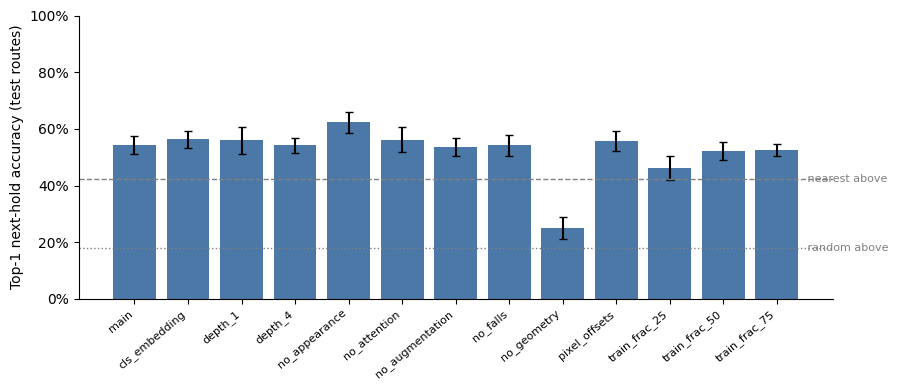

In [ ]:
NEED = {'fold', 'seed', 'top1', 'top3', 'hand', 'joint', 'top1_grab', 'top1_match'}
summ = []
for f in sorted(os.listdir(RES_DIR)):
    if f.endswith('.csv'):
        df_ = pd.read_csv(f'{RES_DIR}/{f}')
        if NEED <= set(df_.columns):
            summ.append(summarize(df_, f[:-4]))
summ = pd.DataFrame(summ)
order = ['main'] + [r for r in summ.run if r != 'main']
summ = summ.set_index('run').loc[[r for r in order if r in set(summ.run)]].reset_index()
summ.to_csv(f'{RES_DIR}/summary.csv', index=False)

show = summ[['run', 'folds', 'seeds']].copy()
for c in ['top1', 'top3', 'hand', 'joint', 'top1_grab', 'top1_match']:
    show[c] = [f'{a:.1%} ± {b:.1%}' for a, b in zip(summ[c], summ[f'{c}_std'])]
print(show.to_string(index=False))
print('\nBaselines (mean ± std across folds):')
for c in ['random_top1', 'random_above_top1', 'nearest_above_top1', 'nearest_above_top3', 'lower_hand']:
    print(f'  {c:20s} {bl[c].mean():.1%} ± {bl[c].std():.1%}')

fig, ax = plt.subplots(figsize=(max(6, 0.7 * len(summ)), 4))
ax.bar(range(len(summ)), summ.top1, yerr=summ.top1_std, capsize=3, color='#4c78a8')
for name, y, style in [('nearest above', bl.nearest_above_top1.mean(), '--'),
                       ('random above', bl.random_above_top1.mean(), ':')]:
    ax.axhline(y, color='grey', linestyle=style, lw=1)
    ax.text(len(summ) - 0.5, y, f' {name}', va='center', fontsize=8, color='grey')
ax.set_xticks(range(len(summ)))
ax.set_xticklabels(summ.run, rotation=40, ha='right', fontsize=8)
ax.set_ylabel('Top-1 next-hold accuracy (test routes)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_ylim(0, 1)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/figures/top1.png', dpi=150)
plt.show()

## Cell 12: Prediction pictures

Train one model and draw a few examples: candidate holds outlined, the true next hold with green star and the model's top 3.

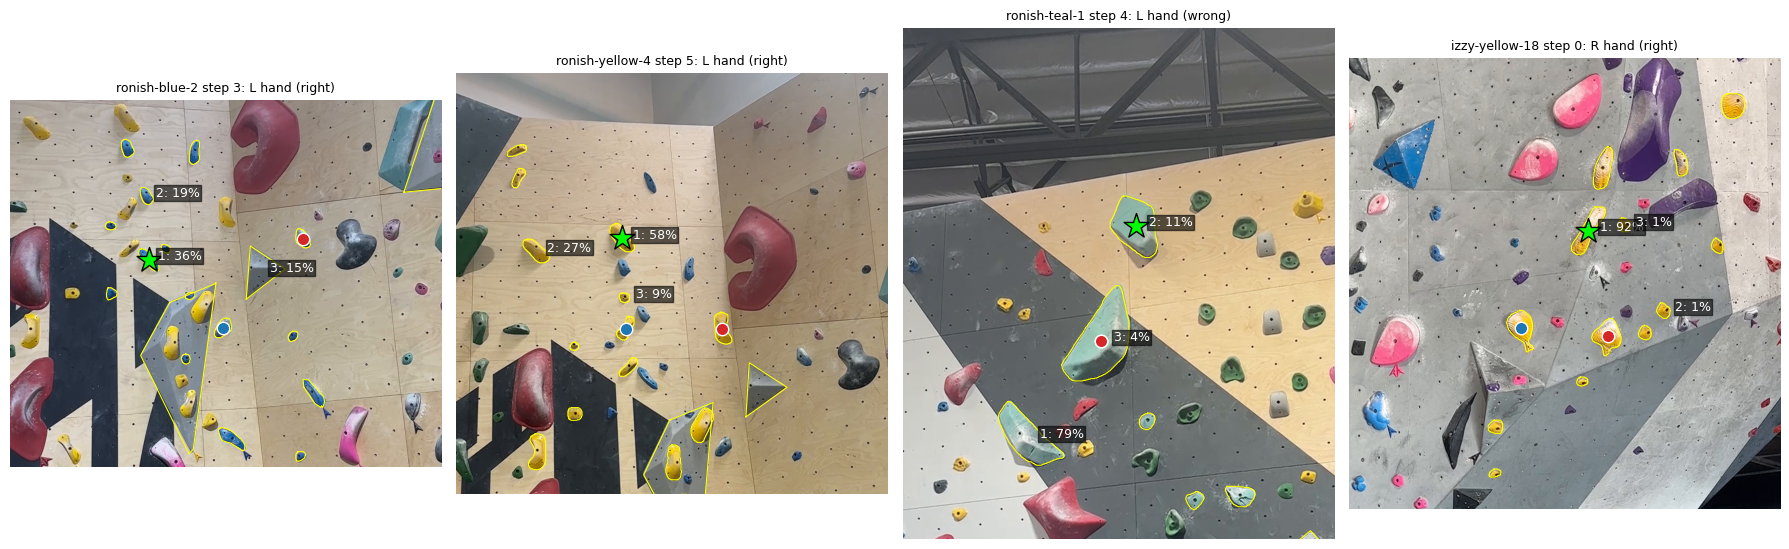

In [28]:
import cv2
MAP_DIR = f'{BASE}/hold-maps'
polys = {normalize_pos(p): v for p, v in json.load(open(f'{MAP_DIR}/hold_polygons.json')).items()}
cands = pd.read_csv(f'{EX_DIR}/candidates.csv')
cands['route_id'] = cands['route_id'].map(norm_route)
HOLD_ID = d['hold_id']

model, _, (tr, va, te) = train_model(1, 0, CFG)
model.eval()
pick = np.random.default_rng(4).choice(te, size=min(4, len(te)), replace=False)
x, emb, m, t, th = make_batch(pick, CFG, False, np.random.default_rng(0))
with torch.no_grad():
    hold, hand = model(*to_t(x, emb, m))
prob = torch.softmax(hold, 1).cpu().numpy()

fig, axes = plt.subplots(1, len(pick), figsize=(4.5 * len(pick), 8))
for ax, b, i in zip(np.atleast_1d(axes), range(len(pick)), pick):
    e_ = ex.iloc[i]
    pos = normalize_pos(e_.position_id)
    img = cv2.imread(f'{MAP_DIR}/{pos}_frame.png')
    ax.imshow(np.zeros((1920, 1080, 3), np.uint8) if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    c = cands[(cands.route_id == e_.route_id) & (cands.position_id.map(normalize_pos) == pos)].set_index('hold_id')
    for h in c.index:
        for part in polys[pos][str(h)]:
            p = np.array(part)
            ax.plot(*np.vstack([p, p[:1]]).T, color='yellow', lw=0.8)
    ax.scatter([e_.L_x], [e_.L_y], s=80, color='tab:blue', edgecolor='white', zorder=4)
    ax.scatter([e_.R_x], [e_.R_y], s=80, color='tab:red', edgecolor='white', zorder=4)
    tgt = c.loc[e_.target_hold]
    ax.scatter(tgt.cx, tgt.cy, marker='*', s=350, color='lime', edgecolor='black', zorder=5)
    for rnk, j in enumerate(np.argsort(-prob[b])[:3]):
        hc = c.loc[int(HOLD_ID[i, j])]
        ax.text(hc.cx + 20, hc.cy, f'{rnk + 1}: {prob[b, j]:.0%}', color='white', fontsize=9,
                bbox=dict(facecolor='black', alpha=0.6, pad=1), zorder=6)
    ys = [e_.L_y, e_.R_y, tgt.cy]
    ax.set_ylim(max(ys) + 300, min(ys) - 300)
    ax.set_xlim(min(e_.L_x, e_.R_x, tgt.cx) - 300, max(e_.L_x, e_.R_x, tgt.cx) + 300)
    ok = 'right' if np.argmax(prob[b]) == t[b] else 'wrong'
    ax.set_title(f'{e_.video} step {e_.step}: {e_.hand} hand ({ok})', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RES_DIR}/figures/predictions_fold1.png', dpi=130, bbox_inches='tight')
plt.show()